# Análisis preliminar – TerriData Dimensión 4

## 1. Importación de datos

In [4]:
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

df = pd.read_excel('TerriData_Dim4.xlsx')
df.head()

,Código Departamento,Departamento,Código Entidad,Entidad,Dimensión,Subcategoría,Indicador,Dato Numérico,Dato Cualitativo,Año,Mes,Fuente,Unidad de Medida
0,41,Huila,41503,Oporapa,Educación,Acceso a la educación,Cobertura bruta en transición,"47,89",NaN,2005,12,Ministerio de Educación Nacional,Porcentaje (el valor está multiplicado por 100)
1,41,Huila,41518,Paicol,Educación,Acceso a la educación,Cobertura bruta en transición,"55,56",NaN,2005,12,Ministerio de Educación Nacional,Porcentaje (el valor está multiplicado por 100)
2,41,Huila,41524,Palermo,Educación,Acceso a la educación,Cobertura bruta en transición,"67,32",NaN,2005,12,Ministerio de Educación Nacional,Porcentaje (el valor está multiplicado por 100)
3,41,Huila,41530,Palestina,Educación,Acceso a la educación,Cobertura bruta en transición,"63,77",NaN,2005,12,Ministerio de Educación Nacional,Porcentaje (el valor está multiplicado por 100)
4,41,Huila,41548,Pital,Educación,Acceso a la educación,Cobertura bruta en transición,"42,15",NaN,2005,12,Ministerio de Educación Nacional,Porcentaje (el valor está multiplicado por 100)


## 2. Dimensión del dataset

In [5]:
print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')
print(f'Memoria: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB')

pd.DataFrame({
    'tipo': df.dtypes,
    'nulos': df.isna().sum(),
    '% nulos': (df.isna().mean() * 100).round(2),
    'únicos': df.nunique()
})

Filas: 452,990 | Columnas: 13
Memoria: 323.7 MB


,tipo,nulos,% nulos,únicos
Código Departamento,int64,0,0.00,34
Departamento,object,0,0.00,34
Código Entidad,int64,0,0.00,1135
Entidad,object,0,0.00,1045
Dimensión,object,0,0.00,1
Subcategoría,object,0,0.00,5
Indicador,object,0,0.00,37
Dato Numérico,object,36734,8.11,20586
Dato Cualitativo,object,450720,99.50,1
Año,int64,0,0.00,23


## 3. Variables cualitativas

In [6]:
cualitativas = ['Departamento', 'Entidad', 'Dimensión', 'Subcategoría',
                'Indicador', 'Dato Cualitativo', 'Fuente', 'Unidad de Medida']

# Cardinalidad, nulos y categoría más frecuente
pd.DataFrame({
    'únicos': df[cualitativas].nunique(),
    'nulos': df[cualitativas].isna().sum(),
    'moda': df[cualitativas].mode().iloc[0],
    'frec. moda': [df[c].value_counts().iloc[0] for c in cualitativas]
})

,únicos,nulos,moda,frec. moda
Departamento,34,0,Antioquia,49763
Entidad,1045,0,Nariño,1636
Dimensión,1,0,Educación,452990
Subcategoría,5,0,Acceso a la educación,306570
Indicador,37,0,Tasa de deserción intra-anual del sector ofici...,24868
Dato Cualitativo,1,450720,preliminar,2270
Fuente,8,0,Ministerio de Educación Nacional,320414
Unidad de Medida,5,0,Porcentaje (el valor está multiplicado por 100),367638


### Niveles de la columna Subcategoría

In [7]:
sub = (df['Indicador'].value_counts(dropna=False)
         .rename_axis('Indicador').reset_index(name='registros'))
sub['%'] = (sub['registros'] / len(df) * 100).round(2)
print(f'{len(sub)} niveles')
sub

37 niveles


,Indicador,registros,%
0,Tasa de deserción intra-anual del sector ofici...,24868,5.49
1,Tasa de repitencia del sector oficial en educa...,24856,5.49
2,Cobertura en educación superior,22699,5.01
3,Cobertura neta en educación - Total,22616,4.99
4,Cobertura neta en educación básica,22616,4.99
5,Cobertura neta en transición,22616,4.99
6,Cobertura neta en educación primaria,22616,4.99
7,Cobertura neta en educación secundaria,22616,4.99
8,Cobertura neta en educación media,22616,4.99
9,Cobertura bruta en educación primaria,22615,4.99


## 4. Variables cuantitativas

`Dato Numérico` se lee como texto con formato `1.033.767,00` (punto de miles, coma decimal); se convierte a número antes de describirla.

In [8]:
df['Dato Numérico'] = pd.to_numeric(
    df['Dato Numérico'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
    errors='coerce'
)
print('Nulos en Dato Numérico:', df['Dato Numérico'].isna().sum())

cuantitativas = ['Dato Numérico', 'Año', 'Mes']
df[cuantitativas].describe().T

Nulos en Dato Numérico: 36734


,count,mean,std,min,25%,50%,75%,max
Dato Numérico,416256.0,154.436160,7136.450592,0.0,42.3,73.79,95.87,2021985.0
Año,452990.0,2015.307868,5.632196,2003.0,2011.0,2016.00,2020.00,2025.0
Mes,452990.0,11.909799,0.676684,6.0,12.0,12.00,12.00,12.0


In [9]:
# Dato Numérico mezcla unidades distintas: describir por unidad de medida
df.groupby('Unidad de Medida')['Dato Numérico'].describe().sort_values('count', ascending=False)

,count,mean,std,min,25%,50%,75%,max
Unidad de Medida,,,,,,,,
Porcentaje (el valor está multiplicado por 100),331335.0,68.699968,40.402880,0.0,41.935,76.55,96.2700,971.92
Porcentaje,45092.0,60.597825,36.593115,0.0,26.570,75.94,95.2325,100.00
Puntos,29476.0,47.526990,4.286948,0.0,44.630,47.56,50.5100,67.67
Numero,10211.0,3661.514935,45427.617805,0.0,207.000,487.00,1150.0000,2021985.00
Años de educación,142.0,8.187183,0.749745,5.0,7.740,8.20,8.6900,10.00


## 5. Series de tiempo por indicador (promedio de todos los municipios)

Cada panel de la grilla 2x2 toma una lista de indicadores; edita `paneles` para cambiar lo que se ve en cada gráfico. El eje Y es el promedio de `Dato Numérico` entre todos los municipios para cada periodo (año-mes). Por defecto se muestran las tasas netas de cobertura.

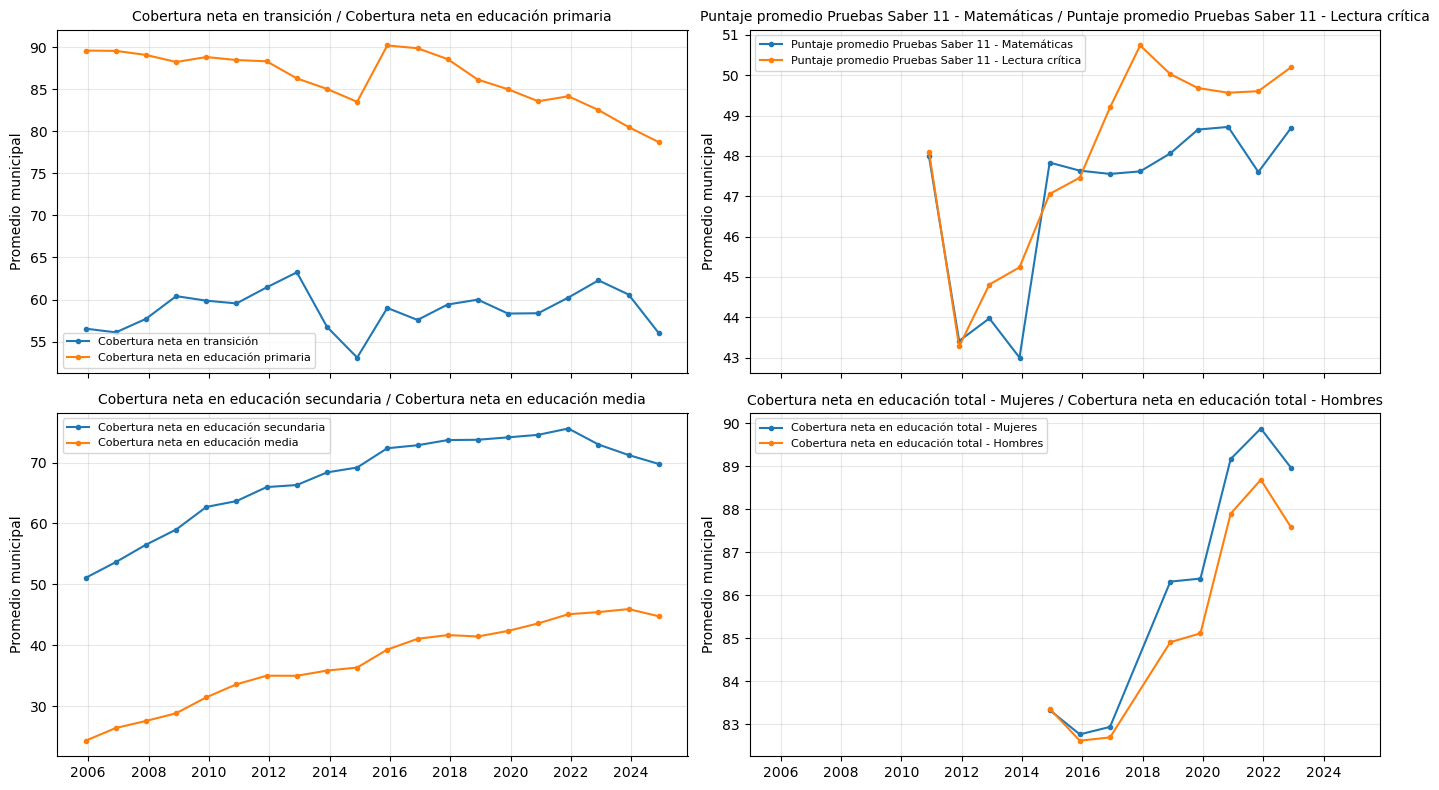

In [10]:
import matplotlib.pyplot as plt

# Lista de indicadores disponibles (para copiar y pegar nombres exactos)
# print(df['Indicador'].unique())

# Un panel por lista: cambia los nombres a mano (pueden ir varios indicadores por panel)
paneles = [
    ['Cobertura neta en transición', 'Cobertura neta en educación primaria'],
    ['Puntaje promedio Pruebas Saber 11 - Matemáticas', 'Puntaje promedio Pruebas Saber 11 - Lectura crítica'],
    ['Cobertura neta en educación secundaria', 'Cobertura neta en educación media'],
    ['Cobertura neta en educación total - Mujeres', 'Cobertura neta en educación total - Hombres'],
]

# Fecha de cada observación y promedio entre municipios por indicador
df['Fecha'] = pd.to_datetime(dict(year=df['Año'], month=df['Mes'], day=1))
promedios = df.groupby(['Indicador', 'Fecha'])['Dato Numérico'].mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, indicadores in zip(axes.flat, paneles):
    for ind in indicadores:
        if ind not in promedios.index.get_level_values('Indicador'):
            print(f'Indicador no encontrado: {ind}')
            continue
        serie = promedios.loc[ind]
        ax.plot(serie.index, serie.values, marker='o', markersize=3, label=ind)
    ax.set_title(' / '.join(indicadores), fontsize=10)
    ax.set_ylabel('Promedio municipal')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

## 6. Cobertura de información por indicador

Para cada indicador se cuentan los departamentos, municipios, años y periodos (año-mes) con al menos un `Dato Numérico` no nulo.

In [11]:
con_dato = df.dropna(subset=['Dato Numérico']).assign(periodo=lambda d: d['Año'] * 100 + d['Mes'])

cobertura = con_dato.groupby('Indicador').agg(
    departamentos=('Código Departamento', 'nunique'),
    municipios=('Código Entidad', 'nunique'),
    años=('Año', 'nunique'),
    meses=('Mes', 'nunique'),
    periodos=('periodo', 'nunique'),
    primer_año=('Año', 'min'),
    último_año=('Año', 'max'),
).sort_values(['municipios', 'años'], ascending=False)

cobertura

,departamentos,municipios,años,meses,periodos,primer_año,último_año
Indicador,,,,,,,
Tasa de deserción intra-anual del sector oficial en educación básica y media (Desde transición hasta once),34,1135,22,1,22,2003,2024
Tasa de repitencia del sector oficial en educación básica y media (Desde transición hasta once),34,1135,22,1,22,2003,2024
Cobertura bruta en educación - Total,34,1135,20,1,20,2005,2024
Cobertura bruta en educación básica,34,1135,20,1,20,2005,2024
Cobertura bruta en educación media,34,1135,20,1,20,2005,2024
Cobertura bruta en educación primaria,34,1135,20,1,20,2005,2024
Cobertura bruta en educación secundaria,34,1135,20,1,20,2005,2024
Cobertura bruta en transición,34,1135,20,1,20,2005,2024
Cobertura en educación superior,34,1135,20,1,20,2005,2024


# Análisis Geojsons

## 1. Importación Datos

In [12]:
import geopandas as gpd

dptos = gpd.read_file('MGN_ANM_DPTOS.geojson')
mpios = gpd.read_file('MGN_ANM_MPIOS.geojson')

print(f'DPTOS: {dptos.shape[0]} filas x {dptos.shape[1]} columnas | CRS: {dptos.crs}')
print(f'MPIOS: {mpios.shape[0]} filas x {mpios.shape[1]} columnas | CRS: {mpios.crs}')
mpios.head()

ModuleNotFoundError: No module named 'geopandas'

## 2. Cardinalidad

Cantidad de departamentos y municipios en cada archivo (únicos por código, no por nombre, porque hay nombres de municipio repetidos).

In [ ]:
pd.DataFrame({
    'departamentos': [dptos['DPTO_CCDGO'].nunique(), mpios['DPTO_CCDGO'].nunique()],
    'municipios': [None, mpios['MPIO_CDPMP'].nunique()],
    'filas (features)': [len(dptos), len(mpios)],
}, index=['MGN_ANM_DPTOS', 'MGN_ANM_MPIOS'])

,departamentos,municipios,filas (features)
MGN_ANM_DPTOS,33,NaN,33
MGN_ANM_MPIOS,33,1122.0,1122


## 3. Atributos

Todas las columnas de información adicional de cada archivo (la geometría se lista aparte) con su tipo, nulos y cardinalidad.

In [ ]:
for nombre, gdf in [('MGN_ANM_DPTOS', dptos), ('MGN_ANM_MPIOS', mpios)]:
    attrs = gdf.drop(columns='geometry')
    print(f'--- {nombre}: {attrs.shape[1]} atributos + geometría ({gdf.geom_type.unique().tolist()}) ---')
    display(pd.DataFrame({
        'tipo': attrs.dtypes,
        'nulos': attrs.isna().sum(),
        'únicos': attrs.nunique(),
        'ejemplo': attrs.iloc[0],
    }))
    display(attrs.describe().T)

--- MGN_ANM_DPTOS: 8 atributos + geometría (['Polygon', 'MultiPolygon']) ---


,tipo,nulos,únicos,ejemplo
DPTO_CCDGO,object,0,33,18
DPTO_CNMBR,object,0,33,CAQUETÁ
VERSION,int32,0,1,2018
AREA,float64,0,33,90103008160.199997
LATITUD,float64,0,33,0.798556
LONGITUD,float64,0,33,-73.959468
TSP16_HOG,int32,0,33,116166
STP27_PERS,int32,0,33,359602


,count,mean,std,min,25%,50%,75%,max
VERSION,33.0,2.018000e+03,0.000000e+00,2.018000e+03,2.018000e+03,2.018000e+03,2.018000e+03,2.018000e+03
AREA,33.0,3.457484e+10,2.918706e+10,4.942425e+07,2.062196e+10,2.413940e+10,4.835322e+10,1.094971e+11
LATITUD,33.0,5.392090e+00,3.477856e+00,-1.546228e+00,2.727843e+00,5.083342e+00,8.095138e+00,1.290938e+01
LONGITUD,33.0,-7.421370e+01,2.548291e+00,-8.156223e+01,-7.568963e+01,-7.426176e+01,-7.288188e+01,-6.881661e+01
TSP16_HOG,33.0,4.316128e+05,5.476131e+05,7.020000e+03,1.161660e+05,3.096800e+05,4.492750e+05,2.514482e+06
STP27_PERS,33.0,1.338316e+06,1.604827e+06,3.769000e+04,3.596020e+05,9.234720e+05,1.346806e+06,7.181469e+06


--- MGN_ANM_MPIOS: 10 atributos + geometría (['Polygon', 'MultiPolygon']) ---


,tipo,nulos,únicos,ejemplo
DPTO_CCDGO,object,0,33,18
MPIO_CCDGO,object,0,581,001
MPIO_CNMBR,object,0,1037,FLORENCIA
MPIO_CDPMP,object,0,1122,18001
VERSION,int32,0,1,2018
AREA,float64,0,1122,2547637532.26
LATITUD,float64,0,1122,1.749139
LONGITUD,float64,0,1122,-75.558239
TSP16_HOG,int32,0,1062,51430
STP27_PERS,int32,0,1104,156789


,count,mean,std,min,25%,50%,75%,max
VERSION,1122.0,2.018000e+03,0.000000e+00,2.018000e+03,2.018000e+03,2.018000e+03,2.018000e+03,2.018000e+03
AREA,1122.0,1.016907e+09,3.197146e+09,1.583532e+07,1.327252e+08,2.874258e+08,7.040972e+08,6.559721e+10
LATITUD,1122.0,5.602895e+00,2.647821e+00,-3.631323e+00,4.232039e+00,5.536306e+00,7.009220e+00,1.335325e+01
LONGITUD,1122.0,-7.463501e+01,1.681235e+00,-8.171757e+01,-7.577684e+01,-7.473103e+01,-7.344419e+01,-6.700152e+01
TSP16_HOG,1122.0,1.269449e+04,8.366294e+04,4.000000e+01,1.958000e+03,3.691500e+03,7.519750e+03,2.514482e+06
STP27_PERS,1122.0,3.936223e+04,2.424477e+05,1.660000e+02,5.886750e+03,1.135450e+04,2.396675e+04,7.181469e+06


# Procesamiento de los Indicadores

In [14]:
# Rango de años que se incluirá en la tabla de cobertura (ambos inclusive)
anio_min = 2005
anio_max = 2022

In [16]:
# Genera cobertura_neta.csv (formato ancho) para Observable: una fila por entidad-año, una columna por nivel.
indicadores = {
    'Cobertura neta en educación - Total': 'total',
    'Cobertura neta en transición': 'transicion',
    'Cobertura neta en educación primaria': 'primaria',
    'Cobertura neta en educación secundaria': 'secundaria',
    'Cobertura neta en educación media': 'media',
    'Tasa de tránsito inmediato a la educación superior': 'superior',
    'Puntaje promedio Pruebas Saber 11 - Lectura crítica': 'puntaje_lectura',
    'Puntaje promedio Pruebas Saber 11 - Matemáticas': 'puntaje_matematicas'
}

d = df[df['Indicador'].isin(indicadores) & df['Año'].between(anio_min, anio_max)].copy()
d = d[d['Código Entidad'] != 1001]  # 1001 = total nacional
d['ind'] = d['Indicador'].map(indicadores)

w = d.pivot_table(
    index=['Código Departamento', 'Departamento', 'Código Entidad', 'Entidad', 'Año'],
    columns='ind', values='Dato Numérico',
).reset_index()
w.columns.name = None

# Códigos XX000 = fila del departamento; el resto son municipios
w['nivel'] = (w['Código Entidad'] % 1000 == 0).map({True: 'departamento', False: 'municipio'})
w = w.rename(columns={'Código Departamento': 'cod_dpto', 'Departamento': 'departamento',
                      'Código Entidad': 'cod_entidad', 'Entidad': 'entidad', 'Año': 'anio'})

# a) Duplicar las filas de Bogotá (código entidad 11001) para crear la fila de departamento (cod_entidad 11000, nivel 'departamento')
bogota_munis = w[w['cod_entidad'] == 11001].copy()
if not bogota_munis.empty:
    bogota_dptos = bogota_munis.copy()
    bogota_dptos['nivel'] = 'departamento'
    bogota_dptos['cod_entidad'] = 11000
    bogota_dptos['entidad'] = 'BOGOTÁ, D.C.'
    w = pd.concat([w, bogota_dptos], ignore_index=True)

# Códigos con cero a la izquierda para que crucen con MPIO_CDPMP del GeoJSON
w['cod_entidad'] = w['cod_entidad'].astype(str).str.zfill(5)
w['cod_dpto'] = w['cod_dpto'].astype(str).str.zfill(2)

# b) Pre-calcular los índices de calidad y cobertura para cada fila
# Calidad: promedio geométrico de Lectura y Matemáticas
l = w['puntaje_lectura']
m = w['puntaje_matematicas']
w['quality'] = np.where((l.notnull()) & (m.notnull()) & (l > 0) & (m > 0), np.sqrt(l * m), np.nan)

# Cobertura: promedio geométrico ponderado (Primaria 0.5, Secundaria 0.35, Media 0.15)
p = w['primaria']
s = w['secundaria']
med = w['media']
w['coverage'] = np.where(
    (p.notnull()) & (s.notnull()) & (med.notnull()) & (p > 0) & (s > 0) & (med > 0),
    (p ** 0.5) * (s ** 0.35) * (med ** 0.15),
    np.nan
)

cols = ['nivel', 'cod_dpto', 'departamento', 'cod_entidad', 'entidad', 'anio',
        'total', 'transicion', 'primaria', 'secundaria', 'media', 'superior', 
        'puntaje_lectura', 'puntaje_matematicas', 'quality', 'coverage']
        
cobertura_neta = w[cols].round(2)
cobertura_neta.to_csv('cobertura_neta.csv', index=False)
print(f'Años {anio_min}-{anio_max} | filas x columnas: {cobertura_neta.shape}')
cobertura_neta.head()

Años 2005-2022 | filas x columnas: (20368, 16)


,nivel,cod_dpto,departamento,cod_entidad,entidad,anio,total,transicion,primaria,secundaria,media,superior,puntaje_lectura,puntaje_matematicas,quality,coverage
0,departamento,05,Antioquia,05000,Antioquia,2005,88.63,65.15,94.28,63.45,36.20,NaN,NaN,NaN,NaN,71.10
1,departamento,05,Antioquia,05000,Antioquia,2006,90.89,69.12,96.21,65.72,37.09,NaN,NaN,NaN,NaN,72.98
2,departamento,05,Antioquia,05000,Antioquia,2007,90.92,68.26,95.52,68.72,38.95,NaN,NaN,NaN,NaN,74.41
3,departamento,05,Antioquia,05000,Antioquia,2008,91.06,69.06,94.95,70.88,39.48,NaN,NaN,NaN,NaN,75.14
4,departamento,05,Antioquia,05000,Antioquia,2009,93.18,71.74,95.42,74.30,41.57,NaN,NaN,NaN,NaN,77.18
